<a href="https://colab.research.google.com/github/jyryu3161/chembigdata/blob/main/lec10_BBBP_KNN_simple_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BBBP 예측: KNN과 분류 모델 평가 지표 실습

**학습 목표**: Morgan fingerprint 기반 KNN을 학습하고, Stratified K-Fold로 검증한 뒤 혼동행렬 및 여러 분류 지표를 직접 계산합니다. 마지막에는 전체 학습 데이터로 학습하여 `submission.csv`를 생성합니다.

- `target=1`: BBB 투과, `target=0`: BBB 비투과
- 분류 기준: 예측 확률이 **0.5 이상이면 1**
- Google Colab에서 **위에서부터 순서대로 실행**하세요.
- 이 노트북은 교육용 예시로 **KNN의 k=5를 고정**합니다. 하이퍼파라미터 탐색은 하지 않습니다.

## 0. 환경 준비

Colab에는 RDKit이 기본 설치되어 있지 않으므로 한 번 설치합니다. (scikit-learn, pandas, matplotlib은 기본 포함)

In [1]:
!pip install -q rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 25.6 MB/s eta 0:00:00


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Draw, rdFingerprintGenerator

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef,
    roc_auc_score, roc_curve,
    average_precision_score, precision_recall_curve
)

RDLogger.DisableLog("rdApp.*")
SEED = 42

## 1. 데이터 불러오기

대회 파일 4개(`train.csv`, `val.csv`, `test.csv`, `sample_submission.csv`)가 필요합니다.

- 아래 셀을 실행하면 파일 선택 창이 뜹니다. 4개 파일을 한꺼번에 선택해 업로드하세요.

In [3]:
# 파일 4개를 Colab에 업로드합니다.
FILES = ["train.csv", "val.csv", "test.csv", "sample_submission.csv"]

missing_files = []
for filename in FILES:
    if not os.path.exists(filename):
        missing_files.append(filename)

if len(missing_files) > 0:
    from google.colab import files
    print("업로드할 파일:", missing_files)
    files.upload()

train = pd.read_csv("train.csv")
val = pd.read_csv("val.csv")
test = pd.read_csv("test.csv")
sample_sub = pd.read_csv("sample_submission.csv")

print("train:", train.shape)
print("val:", val.shape)
print("test:", test.shape)
print("sample_submission:", sample_sub.shape)
display(train.head())

업로드할 파일: ['train.csv', 'val.csv', 'test.csv', 'sample_submission.csv']


Saving sample_submission.csv to sample_submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv
Saving val.csv to val.csv
train: (1421, 3)
val: (203, 2)
test: (406, 2)
sample_submission: (609, 2)


,sample_id,SMILES,target
0,train_0001,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,0
1,train_0002,COC(=O)[C@@]1(O)CC[C@H]2C3CCC(=O)C4C(=O)C=CC4(...,1
2,train_0003,CN(C)CCc1ccccn1,1
3,train_0004,CC(C)NCC(O)COc1ccc(CC(N)=O)cc1,0
4,train_0005,O=C(Nc1ccc(O)cc1)C(Cl)(Cl)Cl,1


**확인할 점**: `train`에만 `target` 열이 있고, `val`/`test`에는 SMILES만 있습니다.
즉, val/test의 ROC-AUC는 제출 후에야 알 수 있으므로 **모델 선택은 train 안에서 검증**해야 합니다 (4장).

target
0     341
1    1080
Name: count, dtype: int64
양성(BBB+) 비율: 76.0%


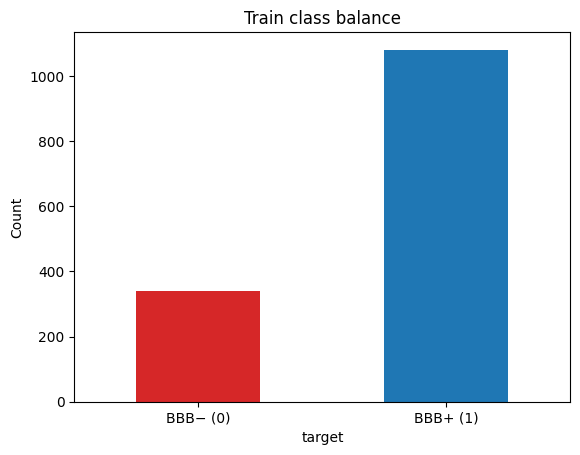

In [4]:
ratio = train["target"].value_counts().sort_index()
print(ratio)
print(f"양성(BBB+) 비율: {train['target'].mean():.1%}")

ratio.plot.bar(color=["tab:red", "tab:blue"])
plt.xticks([0, 1], ["BBB− (0)", "BBB+ (1)"], rotation=0)
plt.ylabel("Count")
plt.title("Train class balance")
plt.show()

**생각해 보기:** `target=1`은 BBB 투과입니다. 데이터의 클래스 비율은 직접 출력된 값으로 판단하세요. 모든 샘플을 다수 클래스로 예측해도 Accuracy는 높을 수 있습니다.

### SMILES 유효성 검사
RDKit으로 SMILES를 분자 객체로 변환합니다.

In [5]:
for name, df in [("train", train), ("val", val), ("test", test)]:
    df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
    print(f"{name}: 파싱 실패 {df['mol'].isna().sum()}개 / {len(df)}개")

train: 파싱 실패 0개 / 1421개
val: 파싱 실패 0개 / 203개
test: 파싱 실패 0개 / 406개


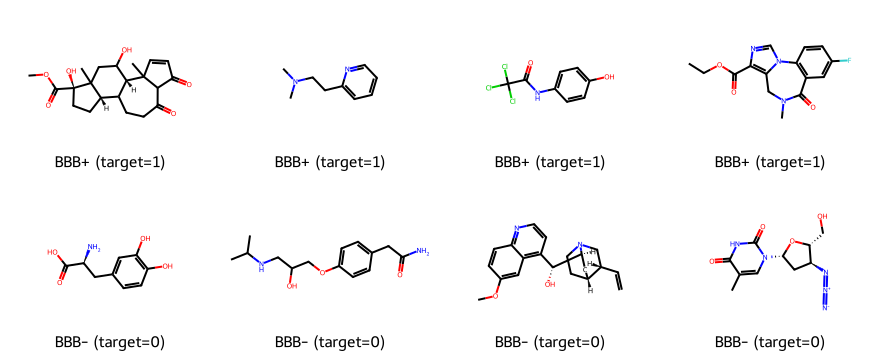

In [6]:
# 클래스별 예시 분자 보기
examples = pd.concat([train[train.target == 1].head(4), train[train.target == 0].head(4)])
Draw.MolsToGridImage(examples["mol"].tolist(), molsPerRow=4, subImgSize=(220, 180),
                     legends=["BBB+ (target=1)" if t == 1 else "BBB- (target=0)" for t in examples["target"]])

## 2. 분자를 숫자 벡터로 바꾸기 (Featurization)

KNN은 "**가까운** 분자들의 라벨을 보고 투표"하는 모델이라, **분자 사이의 거리**를 정의할 수 있어야 합니다.
두 가지 표현을 비교해 봅니다.

| 표현 | 내용 | 거리계산 지표 |
|---|---|---|
| **Morgan fingerprint (ECFP4)** | 원자 주변 반경 2의 부분구조 존재 여부를 2048비트로 표시 | **Jaccard(=1−Tanimoto)** |
| **RDKit descriptor** | 분자량, logP, TPSA, H-결합 주개/받개 수 등 물리화학적 수치 | 표준화 후 Euclidean |

> 💡 BBB 투과는 **TPSA(극성 표면적)**, **H-결합 주개 수**, **logP**, **분자량** 등과 관련이 크다고 알려져 있습니다 (CNS 약물 규칙).
> 그래서 descriptor 기반 KNN도 꽤 경쟁력이 있을 수 있습니다. 직접 비교해 봅시다.

In [7]:
# Morgan fingerprint(ECFP4): 각 분자를 2048개의 0/1 특성으로 표현합니다.
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def morgan_fp(molecules):
    fingerprints = []
    for mol in molecules:
        fp = morgan_gen.GetFingerprintAsNumPy(mol)
        fingerprints.append(fp)
    return np.array(fingerprints, dtype=bool)

X_train_fp = morgan_fp(train["mol"])
X_val_fp = morgan_fp(val["mol"])
X_test_fp = morgan_fp(test["mol"])
y_train = train["target"].to_numpy()

print("Fingerprint shape:", X_train_fp.shape)
print("분자당 1인 비트 수(평균):", X_train_fp.sum(axis=1).mean())

Fingerprint shape: (1421, 2048)
분자당 1인 비트 수(평균): 44.30752990851513


In [8]:
DESC_NAMES = [
    "MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors",
    "NumRotatableBonds", "RingCount", "NumAromaticRings",
    "HeavyAtomCount", "FractionCSP3", "NHOHCount", "NOCount"
]
DESC_FUNCS = dict(Descriptors.descList)

def rdkit_desc(molecules):
    rows = []
    for mol in molecules:
        values = []
        for name in DESC_NAMES:
            values.append(DESC_FUNCS[name](mol))
        rows.append(values)
    return np.array(rows)

X_train_desc = rdkit_desc(train["mol"])
X_val_desc = rdkit_desc(val["mol"])
X_test_desc = rdkit_desc(test["mol"])

desc_table = pd.DataFrame(X_train_desc, columns=DESC_NAMES)
desc_table["target"] = y_train
print("클래스별 descriptor 평균")
display(desc_table.groupby("target").mean().round(2).T)

클래스별 descriptor 평균


target,0,1
MolWt,434.83,330.58
MolLogP,1.13,2.76
TPSA,126.20,56.25
NumHDonors,3.15,1.08
NumHAcceptors,7.21,3.80
NumRotatableBonds,5.34,3.97
RingCount,3.27,3.07
NumAromaticRings,1.38,1.44
HeavyAtomCount,30.06,23.26
FractionCSP3,0.46,0.44


위 표에서 TPSA, H-결합 주개 수, 분자량, logP가 클래스별로 어떻게 다른지 관찰하세요. **어느 쪽이 큰지는 실행 결과로 확인**해야 합니다.

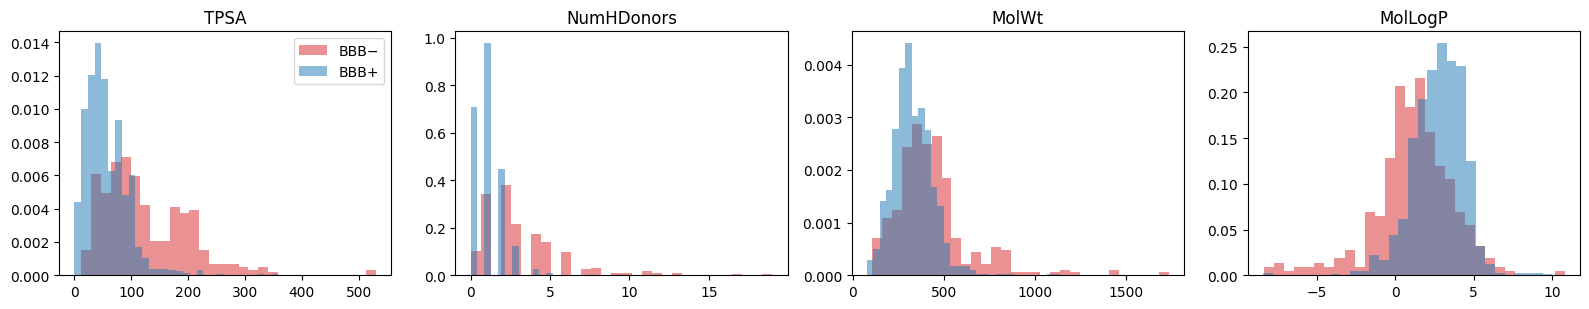

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, name in zip(axes, ["TPSA", "NumHDonors", "MolWt", "MolLogP"]):
    col = DESC_NAMES.index(name)
    for t, color in [(0, "tab:red"), (1, "tab:blue")]:
        ax.hist(X_train_desc[y_train == t, col], bins=30, alpha=0.5, density=True,
                color=color, label=f"BBB{'+' if t else '−'}")
    ax.set_title(name)
axes[0].legend()
plt.tight_layout()
plt.show()

## 3. KNN 분류기 이해하기

새 분자 $x$의 투과 확률을 다음처럼 계산합니다.

1. train 분자 중 $x$와 거리가 가장 가까운 **k개**를 찾는다.
2. 그 k개 이웃 중 양성(1)의 비율 → 예측 확률
   - `weights="uniform"`: 단순 비율
   - `weights="distance"`: 가까운 이웃일수록 더 큰 가중치 ($1/d$)

**특징**
- 하이퍼파라미터: `k`, 거리(`metric`), `weights`
- 거리 스케일에 민감 → descriptor는 반드시 **표준화(StandardScaler)**
- `k`가 작으면 과적합(분산↑), 크면 과소적합(편향↑)

> 📝 `weights="uniform"`이면 확률이 0, 1/k, 2/k, … 처럼 **k+1개 값**만 나옵니다. 동점이 많아져 ROC-AUC가 조금 손해를 볼 수 있으니 `distance` 가중치와 비교해 보세요.

간단한 예로, train의 한 분자에 대한 이웃을 직접 보겠습니다.

이웃 5개 중 양성 비율 = 0.20  →  uniform KNN의 예측 확률


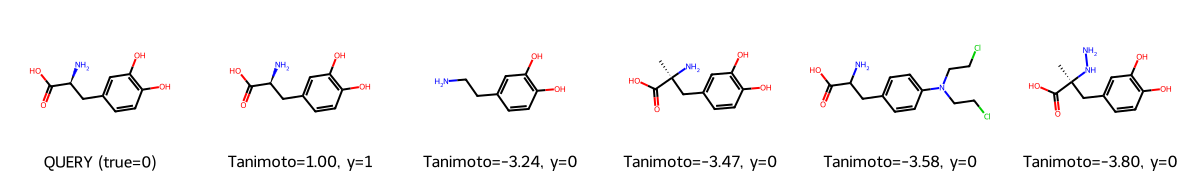

In [10]:
query_idx = 0
knn_demo = KNeighborsClassifier(n_neighbors=5)
knn_demo.fit(X_train_fp, y_train)

# 자기 자신(거리 0)이 결과에 섞여 나오므로, 6개를 찾은 뒤 자기 인덱스를 빼고 5개를 씁니다
dist, idx = knn_demo.kneighbors(X_train_fp[[query_idx]], n_neighbors=6)
dist, idx = dist[0][1:], idx[0][1:]

mols = [train["mol"][query_idx]] + [train["mol"][i] for i in idx]
legends = [f"QUERY (true={y_train[query_idx]})"] + \
          [f"Tanimoto={1-d:.2f}, y={y_train[i]}" for d, i in zip(dist, idx)]
print(f"이웃 5개 중 양성 비율 = {y_train[idx].mean():.2f}  →  uniform KNN의 예측 확률")
Draw.MolsToGridImage(mols, molsPerRow=6, subImgSize=(200, 180), legends=legends)

## 4. Stratified K-Fold 교차검증

`StratifiedKFold`는 데이터의 **0과 1 비율을 각 fold에서 비슷하게 유지**하면서 무작위로 나눕니다. 여기서는 **5개 fold**를 순서대로 검증합니다.

각 fold에서 새로운 KNN을 학습하고 ROC-AUC와 Accuracy를 계산합니다. 이어지는 혼동행렬 실습에서는 설명을 단순하게 하기 위해 **첫 번째 fold의 검증 결과**를 사용합니다.

> 참고: 무작위 분할에서는 구조가 유사한 화합물이 학습·검증 데이터에 모두 포함될 수 있습니다. 따라서 실제 신약개발 모델의 일반화 성능을 평가할 때는 scaffold 기반 분할 등도 고려해야 합니다.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

fold_results = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_fp, y_train), start=1):
    # 학습 데이터와 검증 데이터를 나눕니다.
    X_fold_train = X_train_fp[train_idx]
    X_fold_valid = X_train_fp[valid_idx]
    y_fold_train = y_train[train_idx]
    y_fold_valid = y_train[valid_idx]

    # 매 fold마다 새로운 KNN 모델을 학습합니다.
    model = KNeighborsClassifier(n_neighbors=5, metric="jaccard", algorithm="brute")
    model.fit(X_fold_train, y_fold_train)

    # 검증 데이터의 BBB 투과(1) 예측 확률을 계산합니다.
    prob = model.predict_proba(X_fold_valid)[:, 1]
    pred = (prob >= 0.5).astype(int)

    fold_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_fold_valid, pred),
        "ROC-AUC": roc_auc_score(y_fold_valid, prob)
    })

    # 첫 번째 fold의 결과를 뒤의 지표 실습에 사용합니다.
    if fold == 1:
        y_valid = y_fold_valid
        valid_prob = prob

results_df = pd.DataFrame(fold_results)
display(results_df.round(3))
print("평균 Accuracy:", round(results_df["Accuracy"].mean(), 3))
print("평균 ROC-AUC:", round(results_df["ROC-AUC"].mean(), 3))

,Fold,Accuracy,ROC-AUC
0,1,0.895,0.906
1,2,0.894,0.920
2,3,0.866,0.861
3,4,0.880,0.878
4,5,0.870,0.864


평균 Accuracy: 0.881
평균 ROC-AUC: 0.886


## 5. 혼동행렬(Confusion Matrix)

행은 **실제값**, 열은 **예측값**입니다. `TN`과 `TP`는 정답, `FP`와 `FN`은 오답입니다. 아래부터는 **첫 번째 fold의 검증 데이터**로 계산합니다.

혼동행렬 (행: 실제, 열: 예측)
[[ 51  18]
 [ 12 204]]
TN = 51
FP = 18
FN = 12
TP = 204


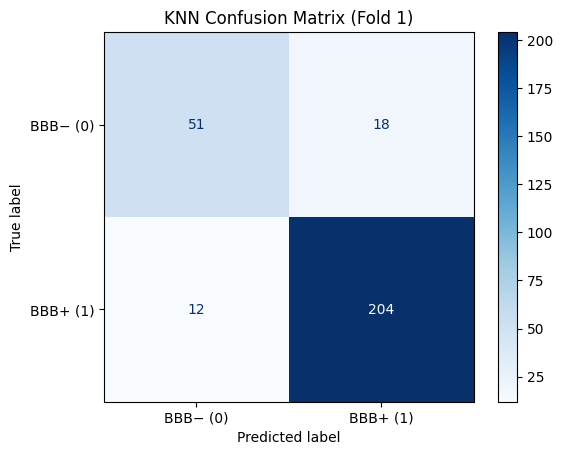

In [12]:
threshold = 0.5
pred_label = (valid_prob >= threshold).astype(int)

cm = confusion_matrix(y_valid, pred_label, labels=[0, 1])
print("혼동행렬 (행: 실제, 열: 예측)")
print(cm)

TN = cm[0, 0]  # 실제 0, 예측 0
FP = cm[0, 1]  # 실제 0, 예측 1
FN = cm[1, 0]  # 실제 1, 예측 0
TP = cm[1, 1]  # 실제 1, 예측 1

print("TN =", TN)
print("FP =", FP)
print("FN =", FN)
print("TP =", TP)

ConfusionMatrixDisplay(cm, display_labels=["BBB− (0)", "BBB+ (1)"]).plot(cmap="Blues", values_format="d")
plt.title("KNN Confusion Matrix (Fold 1)")
plt.show()

### 5-1. 공식으로 지표 직접 계산하기

- Accuracy = (TP+TN) / 전체
- Precision = TP / (TP+FP)
- Recall = TP / (TP+FN)
- Specificity = TN / (TN+FP)
- NPV = TN / (TN+FN)
- F1 = 2×Precision×Recall / (Precision+Recall)

In [13]:
# 직접 계산: 0으로 나누는 상황을 피하기 위해 분모를 확인합니다.
accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
npv = TN / (TN + FN) if (TN + FN) > 0 else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
balanced_accuracy = (recall + specificity) / 2
fpr = FP / (FP + TN) if (FP + TN) > 0 else 0

print(f"Accuracy          = {accuracy:.3f}")
print(f"Precision (PPV)   = {precision:.3f}")
print(f"Recall (TPR)      = {recall:.3f}")
print(f"Specificity (TNR) = {specificity:.3f}")
print(f"NPV               = {npv:.3f}")
print(f"F1 score          = {f1:.3f}")
print(f"Balanced Accuracy = {balanced_accuracy:.3f}")
print(f"FPR = 1 - Specificity = {fpr:.3f}")

Accuracy          = 0.895
Precision (PPV)   = 0.919
Recall (TPR)      = 0.944
Specificity (TNR) = 0.739
NPV               = 0.810
F1 score          = 0.932
Balanced Accuracy = 0.842
FPR = 1 - Specificity = 0.261


### 5-2. scikit-learn의 함수로 계산하기

직접 계산한 값과 라이브러리 계산 값이 같은지 비교합니다. **ROC-AUC와 AP는 0/1 예측값이 아니라 예측 확률을 사용**합니다.

In [14]:
metric_values = {
    "Accuracy": accuracy_score(y_valid, pred_label),
    "Precision (PPV)": precision_score(y_valid, pred_label, zero_division=0),
    "Recall (Sensitivity)": recall_score(y_valid, pred_label, zero_division=0),
    "Specificity": specificity,
    "NPV": npv,
    "F1": f1_score(y_valid, pred_label, zero_division=0),
    "Balanced Accuracy": balanced_accuracy_score(y_valid, pred_label),
    "MCC": matthews_corrcoef(y_valid, pred_label),
    "ROC-AUC": roc_auc_score(y_valid, valid_prob),
    "Average Precision (AP)": average_precision_score(y_valid, valid_prob)
}

metric_table = pd.DataFrame({
    "지표": list(metric_values.keys()),
    "값": list(metric_values.values())
})
display(metric_table.round(3))

print("Accuracy 수동 계산:", round(accuracy, 3))
print("Accuracy 라이브러리:", round(accuracy_score(y_valid, pred_label), 3))

,지표,값
0,Accuracy,0.895
1,Precision (PPV),0.919
2,Recall (Sensitivity),0.944
3,Specificity,0.739
4,NPV,0.810
5,F1,0.932
6,Balanced Accuracy,0.842
7,MCC,0.706
8,ROC-AUC,0.906
9,Average Precision (AP),0.951


Accuracy 수동 계산: 0.895
Accuracy 라이브러리: 0.895


## 6. ROC 곡선과 Precision–Recall 곡선

두 곡선은 **확률 임계값을 바꿀 때** 모델이 어떻게 동작하는지 보여줍니다. ROC-AUC와 AP는 예측 **확률(점수)**에서 계산합니다.

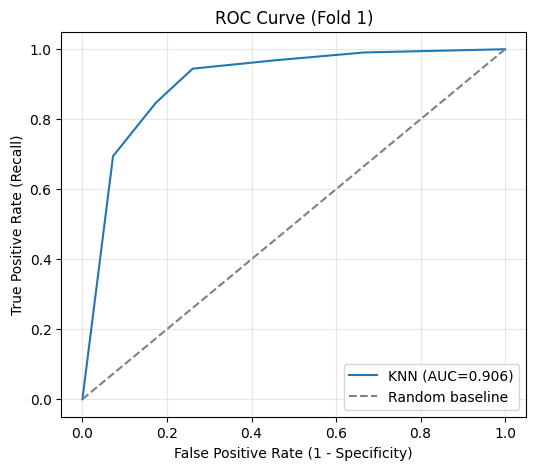

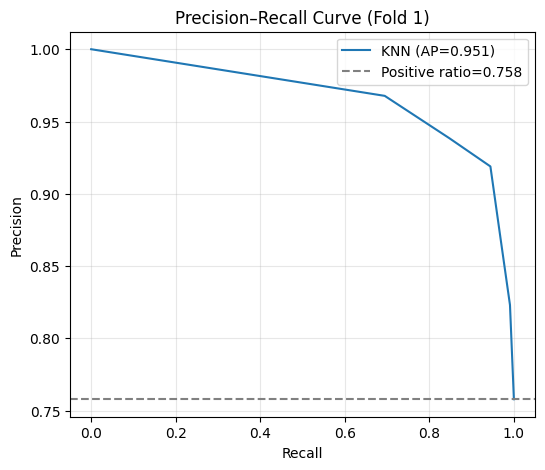

In [15]:
roc_fpr, roc_tpr, roc_thresholds = roc_curve(y_valid, valid_prob)
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_valid, valid_prob)

auc_value = roc_auc_score(y_valid, valid_prob)
ap_value = average_precision_score(y_valid, valid_prob)
positive_ratio = y_valid.mean()

plt.figure(figsize=(6, 5))
plt.plot(roc_fpr, roc_tpr, label=f"KNN (AUC={auc_value:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random baseline")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve (Fold 1)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(6, 5))
plt.plot(pr_recall, pr_precision, label=f"KNN (AP={ap_value:.3f})")
plt.axhline(positive_ratio, linestyle="--", color="gray", label=f"Positive ratio={positive_ratio:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve (Fold 1)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. 임계값(Threshold)에 따른 지표 변화

예측 확률이 **임계값 이상이면 1**로 분류합니다. 0.3 / 0.5 / 0.7로 바꾸면서 Recall, Specificity, FP, FN이 어떻게 달라지는지 확인합니다.

In [16]:
threshold_results = []

for threshold in [0.3, 0.5, 0.7]:
    pred = (valid_prob >= threshold).astype(int)
    matrix = confusion_matrix(y_valid, pred, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()

    row = {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) > 0 else 0,
        "F1": f1_score(y_valid, pred, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }
    threshold_results.append(row)

threshold_table = pd.DataFrame(threshold_results)
display(threshold_table.round(3))

,Threshold,Accuracy,Precision,Recall,Specificity,F1,TN,FP,FN,TP
0,0.3,0.867,0.871,0.968,0.551,0.917,38,31,7,209
1,0.5,0.895,0.919,0.944,0.739,0.932,51,18,12,204
2,0.7,0.842,0.938,0.847,0.826,0.891,57,12,33,183


## 8. 최종 KNN 학습 및 `submission.csv` 만들기

평가 실습에서 사용한 **KNN(k=5, uniform weights)**을 그대로 사용합니다. 하이퍼파라미터 탐색 없이 **전체 train** 데이터로 다시 학습하고, val·test의 예측 확률을 제출 양식에 맞춰 저장합니다.

In [17]:
# 전체 train 데이터로 고정된 KNN 모델을 학습합니다.
final_model = KNeighborsClassifier(n_neighbors=5, metric="jaccard", algorithm="brute")
final_model.fit(X_train_fp, y_train)

# val과 test에는 정답이 없으므로 BBB 투과(1) 확률만 예측합니다.
val_prob = final_model.predict_proba(X_val_fp)[:, 1]
test_prob = final_model.predict_proba(X_test_fp)[:, 1]

val_pred = pd.DataFrame({"sample_id": val["sample_id"], "prediction": val_prob})
test_pred = pd.DataFrame({"sample_id": test["sample_id"], "prediction": test_prob})
all_pred = pd.concat([val_pred, test_pred], ignore_index=True)

# sample_submission.csv에 적힌 sample_id 순서를 그대로 따릅니다.
submission = sample_sub[["sample_id"]].merge(
    all_pred, on="sample_id", how="left", validate="one_to_one"
)

assert len(submission) == len(sample_sub)
assert submission["prediction"].notna().all()

submission.to_csv("submission.csv", index=False)
print("submission.csv 저장 완료!")
display(submission.head())

submission.csv 저장 완료!


,sample_id,prediction
0,val_001,1.0
1,val_002,1.0
2,val_003,1.0
3,val_004,1.0
4,val_005,1.0


In [18]:
# Google Colab에서 파일을 다운로드합니다.
try:
    from google.colab import files
    files.download("submission.csv")
except ImportError:
    print("현재 폴더에 submission.csv 파일이 저장되어 있습니다.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. 확인 문제

1. 혼동행렬에서 **FP**와 **FN**은 각각 무엇을 의미하나요?
2. Recall과 Specificity의 분모는 어떻게 다른가요?
3. BBB 투과(1) 비율이 높을 때 Accuracy만으로 평가하면 왜 문제가 될까요?
4. 임계값을 **0.5에서 0.3으로 낮추면** Recall과 Specificity는 어떤 방향으로 변하나요?
5. **ROC-AUC**는 0/1 예측값 대신 왜 예측 확률로 계산할까요?

**제출:** 마지막까지 실행하여 `submission.csv`를 다운로드합니다.